# Pytorch tensors

https://docs.pytorch.org/tutorials/beginner/introyt/introyt1_tutorial.html

In [42]:
import torch

Few ways to create tensors.

In [3]:
x = torch.rand(5, 3)
print(x)
x.dtype

tensor([[0.2267, 0.2528, 0.6119],
        [0.1011, 0.8053, 0.5349],
        [0.9214, 0.5789, 0.4321],
        [0.6809, 0.8454, 0.5452],
        [0.0444, 0.3941, 0.5193]])


torch.float32

In [4]:
z = torch.zeros(5, 3)
print(z)
z.dtype

tensor([[0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.]])


torch.float32

In [45]:
i = torch.ones(5, 3, dtype=torch.int16)
print(i)
i.dtype

tensor([[1, 1, 1],
        [1, 1, 1],
        [1, 1, 1],
        [1, 1, 1],
        [1, 1, 1]], dtype=torch.int16)


torch.int16

It's common to initialize tensors using a seed.

In [46]:
# Specify a seed
torch.manual_seed(38745)
r1 = torch.rand(2, 2)
print(r1)
print("\nDifferent tensor\n")
r2 = torch.rand(2, 2)
print(r2)
print("\nRepeated values\n")
torch.manual_seed(38745)
r3 = torch.rand(2, 2)
print(r3)

tensor([[0.8906, 0.1344],
        [0.0233, 0.6456]])

Different tensor

tensor([[0.2255, 0.4645],
        [0.6271, 0.2516]])

Repeated values

tensor([[0.8906, 0.1344],
        [0.0233, 0.6456]])


Arithmetic operations on tensors

In [7]:
ones = torch.ones(2, 3)
print(ones)

twos = torch.ones(2, 3) * 2
print(twos)

print(ones+twos)
print((ones+twos).shape)

tensor([[1., 1., 1.],
        [1., 1., 1.]])
tensor([[2., 2., 2.],
        [2., 2., 2.]])
tensor([[3., 3., 3.],
        [3., 3., 3.]])
torch.Size([2, 3])


# Building models

In [8]:
import torch
import torch.nn as nn
import torch.nn.functional as F

In [9]:
class LeNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 6, 5)
        self.conv2 = nn.Conv2d(6, 16, 5)
        self.fc1 = nn.Linear(16*5*5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)
    
    def forward(self, x):
        # Max pooling over a (2, 2) window
        x = F.max_pool2d(F.relu(self.conv1(x)), (2, 2))
        # If the size is a square you can only specify a single number
        x = F.max_pool2d(F.relu(self.conv2(x)), 2)
        x = x.view(-1, self.num_flat_features(x))
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x
    
    def num_flat_features(self, x):
        size = x.size()[1:]  # all dimensions except the batch dimension
        num_features = 1
        for s in size:
            num_features *= s
        return num_features


In [10]:
net = LeNet()
print(net)
list(net.parameters())

LeNet(
  (conv1): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1))
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (fc1): Linear(in_features=400, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=10, bias=True)
)


[Parameter containing:
 tensor([[[[-0.1098, -0.0142,  0.0509, -0.0994, -0.1276],
           [-0.0355,  0.1119, -0.0314, -0.1187,  0.1242],
           [-0.0112, -0.1914,  0.1224, -0.0412,  0.0160],
           [ 0.0851,  0.0901,  0.1477, -0.1782, -0.0497],
           [ 0.0587,  0.0049,  0.1062, -0.0269, -0.0536]]],
 
 
         [[[ 0.1379, -0.1130, -0.1139,  0.0510, -0.1859],
           [ 0.0891, -0.0869,  0.0017,  0.0255,  0.0487],
           [ 0.1474, -0.0548, -0.0054, -0.1958,  0.0217],
           [-0.0099, -0.0429, -0.1832, -0.0776,  0.0387],
           [-0.0642,  0.0993, -0.0396, -0.1746, -0.0724]]],
 
 
         [[[-0.0162, -0.0944,  0.1975, -0.0340,  0.0670],
           [-0.0342, -0.1455,  0.1626,  0.1014,  0.0344],
           [-0.1973, -0.1227, -0.0515,  0.1609, -0.1936],
           [-0.0636, -0.1296, -0.1707, -0.1596,  0.1484],
           [ 0.0751,  0.0282, -0.0433, -0.0082,  0.0711]]],
 
 
         [[[-0.1384,  0.0138, -0.0719, -0.1972,  0.1713],
           [-0.1000, -0.0004,  

In [11]:
inp = torch.rand(1, 1, 32, 32) # one image, one color channel, 32x32 pixels
print(f"Image batch shape: {inp.shape}")

out = net(inp)
print(f"Raw output: {out}")
print(f"Output shape: {out.shape}")

Image batch shape: torch.Size([1, 1, 32, 32])
Raw output: tensor([[-0.0528, -0.0761, -0.0219,  0.0766, -0.0330,  0.0483, -0.0708, -0.0144,
         -0.0797,  0.0003]], grad_fn=<AddmmBackward0>)
Output shape: torch.Size([1, 10])


# Datasets and Dataloaders

In [12]:
%matplotlib inline

import torchvision
import torchvision.transforms as transforms

In [13]:
# transform = transforms.Compose([transforms.ToTensor(),
#                                transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616))])

transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

In [14]:
# Download the dataset
train_ds = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

Files already downloaded and verified


In [17]:
# Give dataset to dataloader
train_dl = torch.utils.data.DataLoader(
    train_ds,
    batch_size=4,
    shuffle=True,
    num_workers=2
)

In [18]:
i = iter(train_dl)
imgs, lbs = next(i)

In [19]:
# Visualize the batches the DL serves
import matplotlib.pyplot as plt
import numpy as np

classes = ('plane', 'car', 'bird', 'cat',
           'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

def imshow(img):
    img = img / 2 * 0.5
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    
def conv(img):
    img = img / 2 * 0.5
    npimg = img.numpy()
    return np.transpose(npimg, (1, 2, 0))

In [20]:
itt = iter(lbs)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


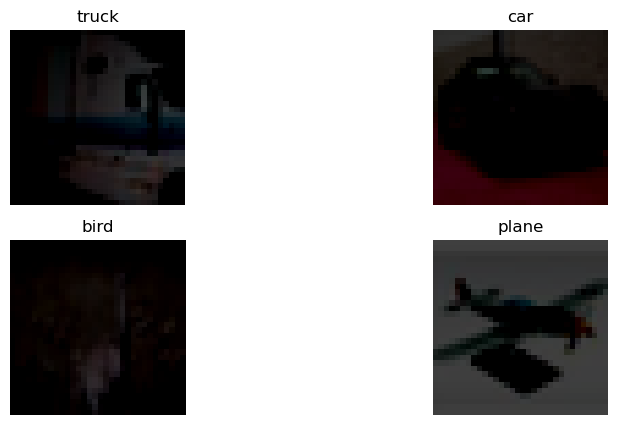

In [21]:
fig, axs = plt.subplots(2, 2, figsize=(10,5))

for ax, img in zip(axs.flat, imgs):
    lb = next(itt)
    ax.imshow(conv(img))
    ax.axis('off')
    ax.set_title(classes[lb])

# Train the model

In [22]:
import torch.optim

In [23]:
transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

train_ds = torchvision.datasets.CIFAR10(root="./data", train=True,
                                       download=True, transform=transform)
train_dl = torch.utils.data.DataLoader(train_ds, batch_size=4,
                                      shuffle=True, num_workers=2)


test_ds = torchvision.datasets.CIFAR10(root="./data", train=False,
                                      download=True, transform=transform)
test_dl = torch.utils.data.DataLoader(test_ds, batch_size=4,
                                     shuffle=False, num_workers=2)

classes = ('plane', 'car', 'bird', 'cat',
           'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

Files already downloaded and verified
Files already downloaded and verified


In [24]:
# Construct NN which can handle images with 3 color channels

class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.conv1 = nn.Conv2d(3, 6, 5)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(6, 16, 5)
        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(-1, 16 * 5 * 5)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x

In [26]:
net = Net()

In [29]:
print(net)

Net(
  (conv1): Conv2d(3, 6, kernel_size=(5, 5), stride=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (fc1): Linear(in_features=400, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=10, bias=True)
)


In [32]:
list(net.parameters())

[Parameter containing:
 tensor([[[[ 0.0798,  0.0104, -0.0266,  0.0586, -0.1089],
           [-0.0331,  0.0400, -0.0697,  0.0053,  0.0461],
           [ 0.0318,  0.0136,  0.0297, -0.0875, -0.0999],
           [ 0.1098,  0.0193,  0.0943,  0.0385,  0.1043],
           [-0.0016, -0.0843, -0.0560, -0.0994, -0.0839]],
 
          [[ 0.0467,  0.0540, -0.0026,  0.1132, -0.0924],
           [ 0.0395, -0.0360,  0.0044,  0.0058, -0.0823],
           [ 0.0820, -0.0768, -0.0855,  0.1022, -0.0865],
           [ 0.0612,  0.0205,  0.0120, -0.0760, -0.1060],
           [-0.0024,  0.0645, -0.0581,  0.1036,  0.0847]],
 
          [[-0.0609,  0.0492, -0.0347,  0.0804, -0.0917],
           [ 0.0110, -0.0324, -0.0593, -0.0716,  0.0667],
           [-0.0401,  0.0287, -0.0587,  0.0181, -0.0883],
           [ 0.0710, -0.0649,  0.0424,  0.0536,  0.0739],
           [-0.0612,  0.0182,  0.0954, -0.0929, -0.0409]]],
 
 
         [[[-0.0096, -0.0110, -0.0272,  0.0285, -0.0429],
           [-0.0445, -0.1044,  0.0674

In [33]:
# Loss and optimizer
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(net.parameters(), lr=0.001, momentum=0.9)

In [34]:
# Training loop
for epoch in range(2):
    running_loss = 0.0
    for i, data in enumerate(train_dl):
        inputs, labels = data
        
        # Zero parameter gradients
        optimizer.zero_grad()
        
        # Forward pass
        outputs = net(inputs)
        loss = loss_fn(outputs, labels)
        # Backward pass
        loss.backward()
        # Optimization
        optimizer.step()
        
        # Stats
        running_loss += loss.item()
        if i % 2000 == 1999:
            print(f"epoch: {epoch + 1}, Running loss: {running_loss / 2000:.5f}")
            running_loss = 0.0
            
print("Finished training")

epoch: 1, Running loss: 2.26727
epoch: 1, Running loss: 1.90120
epoch: 1, Running loss: 1.65653
epoch: 1, Running loss: 1.56268
epoch: 1, Running loss: 1.50220
epoch: 1, Running loss: 1.48104
epoch: 2, Running loss: 1.40444
epoch: 2, Running loss: 1.37482
epoch: 2, Running loss: 1.36180
epoch: 2, Running loss: 1.31515
epoch: 2, Running loss: 1.29208
epoch: 2, Running loss: 1.27210
Finished training


In [35]:
# Check model on test ds
correct = 0
total = 0
with torch.no_grad():
    for data in test_dl:
        images, labels = data
        outputs = net(images)
        _, predicted = torch.max(outputs.data, 1) # 1 is dimension
        total += labels.size(0)
        correct += (predicted == labels).sum().item() # match predicted index with label

print(f"Accuracy of the network on the 10000 test images: {100 * correct / total}%")

Accuracy of the network on the 10000 test images: 53.09%


In [39]:
outputs.data.shape

torch.Size([4, 10])

In [40]:
outputs.data

tensor([[-2.2865, -3.0689,  2.3774,  3.5879,  3.4080,  2.4382,  3.9035, -0.0734,
         -5.2614, -3.0998],
        [-2.5287, -3.4092,  1.6968,  3.7688,  0.9739,  4.0728,  0.7837,  1.5792,
         -2.7052, -3.2329],
        [-0.8258, -1.9600,  0.7764,  1.0623,  3.6989,  1.0403,  1.0433,  1.4350,
         -3.3197, -3.1227],
        [-2.2616, -3.7750,  0.5560,  0.8291,  5.2295,  1.8694, -0.9075,  6.8667,
         -5.9095, -3.2200]])

In [41]:
torch.max(outputs.data, 1)

torch.return_types.max(
values=tensor([3.9035, 4.0728, 3.6989, 6.8667]),
indices=tensor([6, 5, 4, 7]))